# 1. Load and inspect the travel bookings
# Replace the catalog and schema with your actual names.

In [0]:
table_name = "/Volumes/damo630_fall_2026/default/multicity_project/multi_city_booking.csv"

bookings_df = spark.read.csv(table_name, header=True, inferSchema=True)

print("Total booking records:", bookings_df.count())

bookings_df.printSchema()

display(bookings_df.limit(10))

Total booking records: 1166835
root
 |-- user_id: integer (nullable = true)
 |-- checkin: date (nullable = true)
 |-- checkout: date (nullable = true)
 |-- city_id: integer (nullable = true)
 |-- device_class: string (nullable = true)
 |-- affiliate_id: integer (nullable = true)
 |-- booker_country: string (nullable = true)
 |-- hotel_country: string (nullable = true)
 |-- utrip_id: string (nullable = true)



user_id,checkin,checkout,city_id,device_class,affiliate_id,booker_country,hotel_country,utrip_id
1000027,2016-08-13,2016-08-14,8183,desktop,7168,Elbonia,Gondal,1000027_1
1000027,2016-08-14,2016-08-16,15626,desktop,7168,Elbonia,Gondal,1000027_1
1000027,2016-08-16,2016-08-18,60902,desktop,7168,Elbonia,Gondal,1000027_1
1000027,2016-08-18,2016-08-21,30628,desktop,253,Elbonia,Gondal,1000027_1
1000033,2016-04-09,2016-04-11,38677,mobile,359,Gondal,Cobra Island,1000033_1
1000033,2016-04-11,2016-04-12,52089,desktop,384,Gondal,Cobra Island,1000033_1
1000033,2016-04-12,2016-04-14,21328,desktop,384,Gondal,Cobra Island,1000033_1
1000033,2016-04-14,2016-04-16,27485,desktop,384,Gondal,Cobra Island,1000033_1
1000033,2016-04-16,2016-04-19,38677,desktop,384,Gondal,Cobra Island,1000033_1
1000045,2016-06-18,2016-06-20,64876,desktop,2790,The Devilfire Empire,Fook Island,1000045_1



## 2. Data Quality Assessment

Before conducting affinity analysis, the dataset
must be evaluated for completeness and consistency.

This stage examines:
- Missing values across all columns
- Number of unique trips and destination cities
- Booking date coverage

These checks help determine whether the data
is suitable for transaction-based analysis.

In [0]:

from pyspark.sql import functions as F

# 2.1 Check missing values across all columns
missing_values = bookings_df.select([
    F.sum(F.col(c).isNull().cast("int")).alias(c)
    for c in bookings_df.columns
])

print("Missing values by column:")
display(missing_values)

# 2.2 Summarize trips, cities, and booking dates
dataset_summary = bookings_df.agg(
    F.countDistinct("utrip_id").alias("unique_trips"),
    F.countDistinct("city_id").alias("unique_cities"),
    F.min("checkin").alias("earliest_checkin"),
    F.max("checkout").alias("latest_checkout")
)

print("Dataset summary:")
display(dataset_summary)


Missing values by column:


user_id,checkin,checkout,city_id,device_class,affiliate_id,booker_country,hotel_country,utrip_id
0,0,0,0,0,0,0,0,0


Dataset summary:


unique_trips,unique_cities,earliest_checkin,latest_checkout
217686,39901,2015-12-31,2017-02-28



## 3. Transaction Preparation

The booking-level dataset is transformed into
trip-level transactions for affinity analysis.

Each unique trip ID represents one transaction.
Its basket contains the distinct destination cities
booked within that trip.

Duplicate city visits within the same trip are
counted only once.

In [0]:

from pyspark.sql import functions as F

# 3.1 Check records with invalid trip/city identifiers
quality_checks = bookings_df.agg(
    F.sum(
        (F.col("utrip_id").isNull() |
         (F.trim(F.col("utrip_id")) == "")).cast("int")
    ).alias("invalid_trip_ids"),
    F.sum(
        F.col("city_id").isNull().cast("int")
    ).alias("missing_city_ids"),
    F.sum(
        (F.col("checkout") < F.col("checkin")).cast("int")
    ).alias("invalid_date_order")
)

display(quality_checks)

# 3.2 Keep records with valid transaction identifiers
valid_bookings_df = bookings_df.filter(
    F.col("utrip_id").isNotNull() &
    (F.trim(F.col("utrip_id")) != "") &
    F.col("city_id").isNotNull()
)

# 3.3 Build distinct city baskets
transactions_df = (
    valid_bookings_df
    .groupBy("utrip_id")
    .agg(
        F.array_sort(
            F.collect_set("city_id")
        ).alias("cities")
    )
    .withColumn("basket_size", F.size("cities"))
)

# 3.4 Inspect example baskets without displaying user IDs
display(
    transactions_df
    .select("cities", "basket_size")
    .limit(10)
)

# 3.5 Summarize transaction sizes
basket_summary = transactions_df.agg(
    F.count("*").alias("total_transactions"),
    F.round(F.avg("basket_size"), 2).alias("avg_cities_per_trip"),
    F.min("basket_size").alias("min_cities"),
    F.max("basket_size").alias("max_cities")
)

display(basket_summary)

invalid_trip_ids,missing_city_ids,invalid_date_order
0,0,0


cities,basket_size
"List(26022, 59134, 63151)",3
"List(7240, 7549, 13530, 23542, 26235, 27115, 29738, 30520, 43560, 53777, 63342, 66648)",12
"List(6788, 12426, 17127, 52815, 53213)",5
"List(5984, 25398, 28864, 34908, 38586, 52815, 62399)",7
"List(10485, 14549)",2
"List(2200, 37964, 53633, 61058)",4
"List(7653, 23921, 29319)",3
"List(55, 1912, 21996, 23921, 23935, 48483)",6
"List(2919, 37128, 45347, 67361)",4
"List(4866, 6327, 36709, 55133, 61320)",5


total_transactions,avg_cities_per_trip,min_cities,max_cities
217686,4.75,1,39



## 4. Exploratory Data Analysis

### 4.1 Distribution of Cities per Trip

This analysis examines the number of unique destination
cities included in each trip.

The goal is to understand travel patterns and determine
whether the dataset is suitable for association rule mining.

Trips containing only one city cannot produce
city-to-city association rules.

total_trips,avg_cities_per_trip,max_cities_per_trip,single_city_trips,multi_city_trips
217686,4.75,39,5025,212661


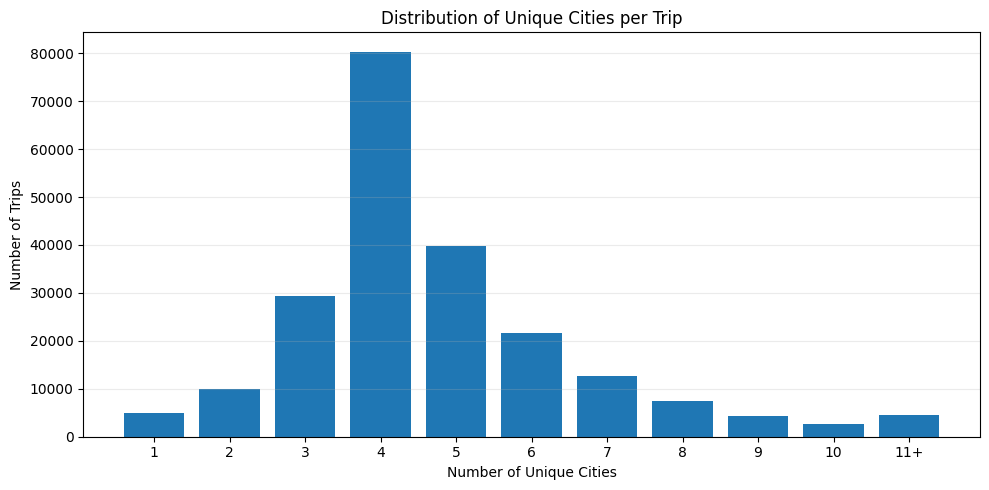

In [0]:

from pyspark.sql import functions as F
import matplotlib.pyplot as plt

# 4.1 Summary statistics
trip_stats = transactions_df.agg(
    F.count("*").alias("total_trips"),
    F.round(F.avg("basket_size"), 2).alias("avg_cities_per_trip"),
    F.max("basket_size").alias("max_cities_per_trip"),
    F.sum(F.when(F.col("basket_size") == 1, 1)
          .otherwise(0)).alias("single_city_trips"),
    F.sum(F.when(F.col("basket_size") >= 2, 1)
          .otherwise(0)).alias("multi_city_trips")
)

display(trip_stats)

# 4.2 Group trip sizes for visualization
# Trips with 11 or more cities are grouped together.

basket_distribution = (
    transactions_df
    .withColumn(
        "size_group",
        F.when(F.col("basket_size") >= 11, 11)
         .otherwise(F.col("basket_size"))
    )
    .groupBy("size_group")
    .count()
    .orderBy("size_group")
)

# Only a small aggregated table is collected to Python
plot_data = basket_distribution.collect()

labels = [
    "11+" if row["size_group"] == 11
    else str(row["size_group"])
    for row in plot_data
]

counts = [row["count"] for row in plot_data]

# 4.3 Visualization
plt.figure(figsize=(10, 5))
plt.bar(labels, counts)

plt.title("Distribution of Unique Cities per Trip")
plt.xlabel("Number of Unique Cities")
plt.ylabel("Number of Trips")

plt.grid(axis="y", alpha=0.25)
plt.tight_layout()
plt.show()


### 4.2 Most Frequently Booked Destination Cities

This analysis identifies the most frequently occurring
destination cities across unique travel transactions.

City popularity is measured by the number of distinct
trips containing each city.

This approach avoids counting repeated bookings of the
same destination within a single trip.

The analysis also examines data sparsity, which can
affect the reliability of frequent itemset discovery.


In [0]:

from pyspark.sql import functions as F
import matplotlib.pyplot as plt

# 4.2.1 Count unique trips containing each city

city_frequency_df = (
    transactions_df
    .select(F.explode("cities").alias("city_id"))
    .groupBy("city_id")
    .agg(F.count("*").alias("trip_count"))
)

total_trips = transactions_df.count()

# Calculate support percentage
city_frequency_df = city_frequency_df.withColumn(
    "support_pct",
    F.round(
        F.col("trip_count") / F.lit(total_trips) * 100,
        3
    )
)

# Identify the top 15 cities
top_15_cities = (
    city_frequency_df
    .orderBy(F.desc("trip_count"), F.asc("city_id"))
    .limit(15)
)

print("Top 15 destination cities:")
display(top_15_cities)


Top 15 destination cities:


city_id,trip_count,support_pct
23921,8205,3.769
47499,7328,3.366
55128,7213,3.313
64876,6754,3.103
29319,6434,2.956
36063,6421,2.95
17127,6101,2.803
66648,5790,2.66
17013,5422,2.491
48483,5253,2.413


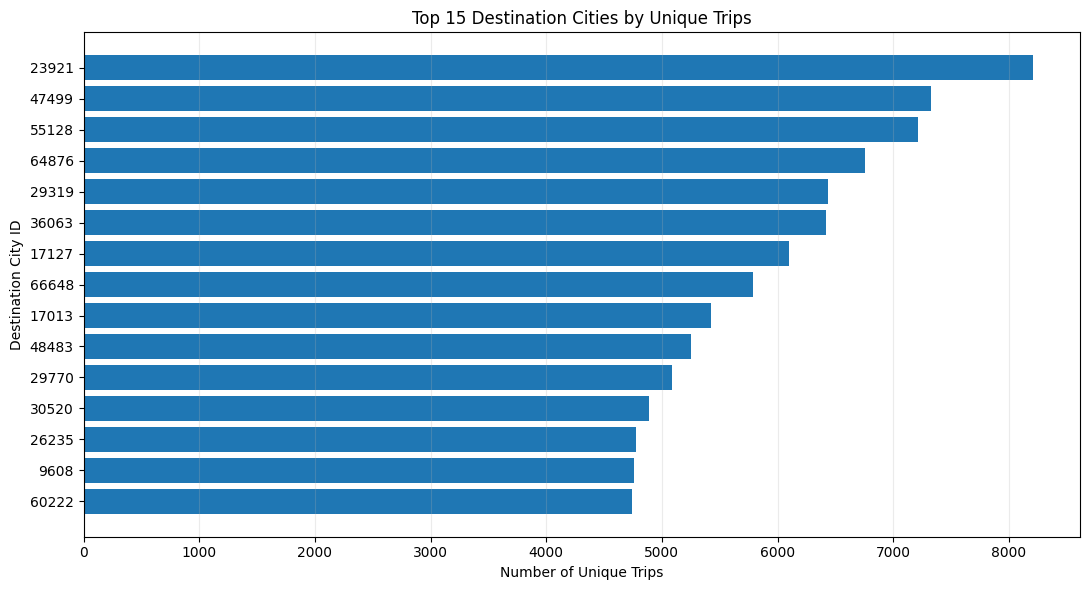

In [0]:

# 4.2.2 Visualize the most frequent cities

top_city_rows = top_15_cities.collect()

city_labels = [
    str(row["city_id"]) for row in top_city_rows
]

trip_counts = [
    row["trip_count"] for row in top_city_rows
]

fig, ax = plt.subplots(figsize=(11, 6))

ax.barh(
    city_labels[::-1],
    trip_counts[::-1]
)

ax.set_title(
    "Top 15 Destination Cities by Unique Trips"
)

ax.set_xlabel("Number of Unique Trips")
ax.set_ylabel("Destination City ID")

ax.grid(axis="x", alpha=0.25)

plt.tight_layout()
plt.show()



### 4.3 Destination Frequency and Data Sparsity

This section evaluates the frequency distribution
of individual destinations.

Cities that appear in very few trips may be
unsuitable for association-rule mining under
a meaningful minimum support threshold.


In [0]:

# 4.3.1 Evaluate destination frequency

sparsity_summary = city_frequency_df.agg(
    F.count("*").alias("total_unique_cities"),

    F.sum(
        F.when(F.col("trip_count") == 1, 1).otherwise(0)
    ).alias("cities_in_one_trip"),

    F.sum(
        F.when(F.col("trip_count") < 10, 1).otherwise(0)
    ).alias("cities_in_fewer_than_10_trips"),

    F.max("trip_count").alias("max_trip_frequency")
)

print("Destination frequency summary:")
display(sparsity_summary)


Destination frequency summary:


total_unique_cities,cities_in_one_trip,cities_in_fewer_than_10_trips,max_trip_frequency
39901,12349,30605,8205



## 5. Frequent Itemset Mining

### 5.1 Minimum Support Selection

Frequent itemset mining identifies destination cities
and city combinations that appear together in a
sufficient number of travel transactions.

An initial minimum support threshold of 0.1% is used.

This relatively low threshold is appropriate for
exploratory analysis because destination frequencies
are highly sparse.

The threshold will be evaluated based on the number
of frequent itemsets discovered.


In [0]:

from pyspark.sql import functions as F
import math

# 5.1 Define minimum support
min_support = 0.001  # 0.1%

total_trips = transactions_df.count()

min_count = math.ceil(total_trips * min_support)

print("Total transactions:", total_trips)
print("Minimum support:", min_support)
print("Minimum required trip count:", min_count)

# 5.2 Generate frequent 1-itemsets
frequent_1_df = (
    city_frequency_df
    .filter(F.col("trip_count") >= min_count)
    .withColumn(
        "support",
        F.col("trip_count") / F.lit(total_trips)
    )
    .orderBy(F.desc("trip_count"))
)

print("Number of frequent 1-itemsets:", frequent_1_df.count())

display(frequent_1_df.limit(20))


Total transactions: 217686
Minimum support: 0.001
Minimum required trip count: 218
Number of frequent 1-itemsets: 815


city_id,trip_count,support_pct,support
23921,8205,3.769,0.03769190485378022
47499,7328,3.366,0.03366316621188317
55128,7213,3.313,0.03313488235348162
64876,6754,3.103,0.03102634069255717
29319,6434,2.956,0.029556333434396332
36063,6421,2.95,0.02949661438953355
17127,6101,2.803,0.02802660713137271
66648,5790,2.66,0.026597943827347648
17013,5422,2.491,0.024907435480462686
48483,5253,2.413,0.02413108789724649



### 5.2 Frequent City Pairs

This stage identifies pairs of destination cities
that appear together within the same trip.

Only cities that satisfy the minimum support
threshold individually are considered as candidates.

Each unordered pair is counted once per trip,
and its support is calculated using the total
number of original transactions.


In [0]:

# 5.3 Keep only cities that meet minimum support
# This reduces the number of candidate pairs.

frequent_city_ids = frequent_1_df.select("city_id")

candidate_baskets_df = (
    transactions_df
    .select(
        "utrip_id",
        F.explode("cities").alias("city_id")
    )
    .join(
        F.broadcast(frequent_city_ids),
        on="city_id",
        how="inner"
    )
    .groupBy("utrip_id")
    .agg(
        F.array_sort(
            F.collect_set("city_id")
        ).alias("cities")
    )
    .filter(F.size("cities") >= 2)
)

# 5.4 Generate unique unordered city pairs
candidate_pairs_df = (
    candidate_baskets_df
    .select(
        "utrip_id",
        "cities",
        F.posexplode("cities").alias("i", "city_a")
    )
    .select(
        "utrip_id",
        "i",
        "city_a",
        F.posexplode("cities").alias("j", "city_b")
    )
    .filter(F.col("i") < F.col("j"))
)

# 5.5 Count the frequency of each city pair
frequent_2_df = (
    candidate_pairs_df
    .groupBy("city_a", "city_b")
    .agg(F.count("*").alias("trip_count"))
    .filter(F.col("trip_count") >= min_count)
    .withColumn(
        "support",
        F.col("trip_count") / F.lit(total_trips)
    )
    .orderBy(F.desc("trip_count"))
)

print("Number of frequent 2-itemsets:", frequent_2_df.count())

print("Top 20 frequent city pairs:")
display(frequent_2_df.limit(20))


Number of frequent 2-itemsets: 969
Top 20 frequent city pairs:


city_a,city_b,trip_count,support
55128,64876,4022,0.018476153726009022
23921,29319,3847,0.017672243506702313
30520,66648,3792,0.01741958600920592
18417,66648,3174,0.014580634491882804
17013,60222,3152,0.014479571492884246
4932,60222,3070,0.014102882132980532
18417,30520,3020,0.013873193498892902
23921,48483,2878,0.013220877778084028
29319,48483,2797,0.012848782190862067
9608,55128,2693,0.012371029831959795



## 6. Association Rule Mining

### 6.1 Support, Confidence, and Lift

Association rules describe relationships between
destination cities appearing within the same trip.

Support measures the proportion of transactions
containing both destinations.

Confidence measures the probability of observing
the consequent destination given the antecedent.

Lift compares this conditional probability against
the consequent destination's overall frequency.

A lift greater than 1 indicates a positive
association between destinations.

Initial filtering thresholds:
- Minimum support: 0.1%
- Minimum confidence: 20%
- Minimum lift: 1.2

These thresholds will be evaluated against the
number and reliability of rules discovered.


In [0]:

from pyspark.sql import functions as F

# 6.1 Define rule thresholds
min_confidence = 0.20
min_lift = 1.20

# Get the individual city frequencies
city_counts_a = city_frequency_df.select(
    F.col("city_id").alias("city_a"),
    F.col("trip_count").alias("count_a")
)

city_counts_b = city_frequency_df.select(
    F.col("city_id").alias("city_b"),
    F.col("trip_count").alias("count_b")
)

# Join pair frequencies with individual city frequencies
pairs_with_counts = (
    frequent_2_df
    .select(
        "city_a",
        "city_b",
        F.col("trip_count").alias("pair_count")
    )
    .join(city_counts_a, "city_a")
    .join(city_counts_b, "city_b")
)

# Generate A -> B rules
rules_ab = pairs_with_counts.select(
    F.col("city_a").alias("antecedent"),
    F.col("city_b").alias("consequent"),
    "pair_count",
    F.col("count_a").alias("antecedent_count"),
    F.col("count_b").alias("consequent_count")
)

# Generate B -> A rules
rules_ba = pairs_with_counts.select(
    F.col("city_b").alias("antecedent"),
    F.col("city_a").alias("consequent"),
    "pair_count",
    F.col("count_b").alias("antecedent_count"),
    F.col("count_a").alias("consequent_count")
)

# Combine directions and calculate rule metrics
all_rules_df = (
    rules_ab.unionByName(rules_ba)
    .withColumn(
        "support",
        F.col("pair_count") / F.lit(total_trips)
    )
    .withColumn(
        "confidence",
        F.col("pair_count") / F.col("antecedent_count")
    )
    .withColumn(
        "lift",
        F.col("confidence") /
        (F.col("consequent_count") / F.lit(total_trips))
    )
)

print("Total directional rules:", all_rules_df.count())


Total directional rules: 1938


In [0]:

# 6.2 Apply confidence and lift thresholds
strong_rules_df = (
    all_rules_df
    .filter(
        (F.col("confidence") >= min_confidence) &
        (F.col("lift") >= min_lift)
    )
    .orderBy(
        F.desc("lift"),
        F.desc("confidence"),
        F.desc("pair_count")
    )
)

print("Rules meeting thresholds:", strong_rules_df.count())

# Display top 20 rules
top_rules = strong_rules_df.select(
    "antecedent",
    "consequent",
    "pair_count",
    F.round("support", 4).alias("support"),
    F.round("confidence", 3).alias("confidence"),
    F.round("lift", 2).alias("lift")
).limit(20)

display(top_rules)


Rules meeting thresholds: 1299


antecedent,consequent,pair_count,support,confidence,lift
36020,45025,236,0.0011,0.959,513.11
45025,36020,236,0.0011,0.58,513.11
46088,43621,232,0.0011,0.792,443.1
43621,46088,232,0.0011,0.596,443.1
14919,43608,308,0.0014,0.819,428.65
43608,14919,308,0.0014,0.74,428.65
56590,54603,358,0.0016,0.808,396.21
54603,56590,358,0.0016,0.806,396.21
34985,18548,244,0.0011,0.748,387.93
18548,34985,244,0.0011,0.581,387.93



## 7. Business-Oriented Rule Evaluation

### 7.1 Identifying Actionable Association Rules

Association rules are evaluated using support,
confidence, and lift.

Rules with high support represent frequently observed
combinations, while high confidence indicates a
strong conditional relationship.

Lift measures the strength of an association relative
to the consequent city's overall popularity.

The analysis compares rules using multiple metrics
rather than relying exclusively on lift.

Three meaningful rules will be selected for
business interpretation and recommendations.


In [0]:

from pyspark.sql import functions as F
from pyspark.sql.window import Window

# Step 7.1: Apply rule-quality thresholds
qualified_rules_df = all_rules_df.filter(
    (F.col("confidence") >= 0.20) &
    (F.col("lift") >= 1.20)
)

print("Rules meeting quality thresholds:",
      qualified_rules_df.count())

# Step 7.2: Evaluate rules by frequency
print("Top 10 rules by co-booking frequency:")

top_support_rules = (
    qualified_rules_df
    .orderBy(
        F.desc("pair_count"),
        F.desc("confidence")
    )
    .select(
        "antecedent",
        "consequent",
        "pair_count",
        F.round("support", 4).alias("support"),
        F.round("confidence", 3).alias("confidence"),
        F.round("lift", 2).alias("lift")
    )
    .limit(10)
)

display(top_support_rules)

# Step 7.3: Evaluate rules by lift
print("Top 10 rules by lift:")

top_lift_rules = (
    qualified_rules_df
    .orderBy(
        F.desc("lift"),
        F.desc("pair_count")
    )
    .select(
        "antecedent",
        "consequent",
        "pair_count",
        F.round("support", 4).alias("support"),
        F.round("confidence", 3).alias("confidence"),
        F.round("lift", 2).alias("lift")
    )
    .limit(10)
)

display(top_lift_rules)


Rules meeting quality thresholds: 1299
Top 10 rules by co-booking frequency:


antecedent,consequent,pair_count,support,confidence,lift
64876,55128,4022,0.0185,0.595,17.97
55128,64876,4022,0.0185,0.558,17.97
29319,23921,3847,0.0177,0.598,15.86
23921,29319,3847,0.0177,0.469,15.86
30520,66648,3792,0.0174,0.776,29.17
66648,30520,3792,0.0174,0.655,29.17
18417,66648,3174,0.0146,0.806,30.29
66648,18417,3174,0.0146,0.548,30.29
60222,17013,3152,0.0145,0.665,26.71
17013,60222,3152,0.0145,0.581,26.71


Top 10 rules by lift:


antecedent,consequent,pair_count,support,confidence,lift
45025,36020,236,0.0011,0.58,513.11
36020,45025,236,0.0011,0.959,513.11
43621,46088,232,0.0011,0.596,443.1
46088,43621,232,0.0011,0.792,443.1
43608,14919,308,0.0014,0.74,428.65
14919,43608,308,0.0014,0.819,428.65
56590,54603,358,0.0016,0.808,396.21
54603,56590,358,0.0016,0.806,396.21
18548,34985,244,0.0011,0.581,387.93
34985,18548,244,0.0011,0.748,387.93


In [0]:

# Step 8: Select three business-relevant rules

selected_rules_df = (
    qualified_rules_df
    .filter(
        ((F.col("antecedent") == 64876) &
         (F.col("consequent") == 55128)) |
        ((F.col("antecedent") == 18417) &
         (F.col("consequent") == 66648)) |
        ((F.col("antecedent") == 36020) &
         (F.col("consequent") == 45025))
    )
    .select(
        "antecedent",
        "consequent",
        "pair_count",
        F.round("support", 4).alias("support"),
        F.round("confidence", 3).alias("confidence"),
        F.round("lift", 2).alias("lift")
    )
    .orderBy(F.desc("pair_count"))
)

display(selected_rules_df)

assert selected_rules_df.count() == 3, \
    "Expected three selected rules."


antecedent,consequent,pair_count,support,confidence,lift
64876,55128,4022,0.0185,0.595,17.97
18417,66648,3174,0.0146,0.806,30.29
36020,45025,236,0.0011,0.959,513.11



## 9. Frequent 3-Itemset Mining

### 9.1 Candidate Generation Using the Apriori Principle

Frequent 3-itemsets identify groups of three
destination cities that occur together within
the same trip.

To improve computational efficiency, candidate
triples are generated only when all three
constituent city pairs are frequent.

The same minimum support threshold of 0.1%
is used to ensure consistency with the
previous itemset analysis.


In [0]:

from pyspark.sql import functions as F

# Create three views of frequent city pairs
ab = frequent_2_df.select(
    F.col("city_a"),
    F.col("city_b")
)

ac = frequent_2_df.select(
    F.col("city_a"),
    F.col("city_b").alias("city_c")
)

bc = frequent_2_df.select(
    F.col("city_a").alias("city_b"),
    F.col("city_b").alias("city_c")
)

# A candidate triple must have all 3 frequent pairs:
# (A,B), (A,C), and (B,C)

candidate_3_df = (
    ab.join(ac, on="city_a")
      .filter(F.col("city_b") < F.col("city_c"))
      .join(bc, on=["city_b", "city_c"])
      .select("city_a", "city_b", "city_c")
      .distinct()
)

print("Candidate 3-itemsets:", candidate_3_df.count())

display(candidate_3_df.limit(10))


Candidate 3-itemsets: 1092


city_a,city_b,city_c
17127,47378,64876
3082,47486,47976
23983,25701,40413
19448,26436,46026
9698,55763,61320
40325,51999,60143
42356,45325,62611
22065,46854,57658
28545,45188,60274
47389,51291,66648


In [0]:

# 9.2 Match candidate triples against actual trips

# Each candidate pair occurs only once per trip
pair_trip_df = candidate_pairs_df.select(
    "utrip_id", "city_a", "city_b"
)

# Match candidate pairs and verify the third city
triple_occurrences_df = (
    pair_trip_df
    .join(
        F.broadcast(candidate_3_df),
        on=["city_a", "city_b"],
        how="inner"
    )
    .join(
        transactions_df.select("utrip_id", "cities"),
        on="utrip_id",
        how="inner"
    )
    .filter(
        F.array_contains(F.col("cities"), F.col("city_c"))
    )
)

# Count trips containing each complete triple
frequent_3_df = (
    triple_occurrences_df
    .groupBy("city_a", "city_b", "city_c")
    .agg(F.count("*").alias("trip_count"))
    .filter(F.col("trip_count") >= min_count)
    .withColumn(
        "support",
        F.round(
            F.col("trip_count") / F.lit(total_trips),
            6
        )
    )
    .orderBy(
        F.desc("trip_count"),
        F.asc("city_a"),
        F.asc("city_b"),
        F.asc("city_c")
    )
)

print("Frequent 3-itemsets:", frequent_3_df.count())

print("Top 15 frequent city triples:")
display(frequent_3_df.limit(15))


Frequent 3-itemsets: 405
Top 15 frequent city triples:


city_a,city_b,city_c,trip_count,support
18417,30520,66648,2571,0.011811
9608,55128,64876,2074,0.009527
4932,17013,60222,1920,0.00882
17127,55128,64876,1866,0.008572
23921,29319,48483,1756,0.008067
9608,17127,55128,1423,0.006537
9608,17127,64876,1341,0.00616
23714,30520,66648,1132,0.0052
23921,29319,65322,1007,0.004626
18417,23714,30520,978,0.004493



## 10. Visualization of Frequent Three-City Patterns

This visualization presents the ten most frequent
three-city combinations discovered in the dataset.

Each bar represents the number of distinct trips
containing all three cities.

The results help identify recurring multi-destination
booking patterns and potential opportunities
for travel package recommendations.


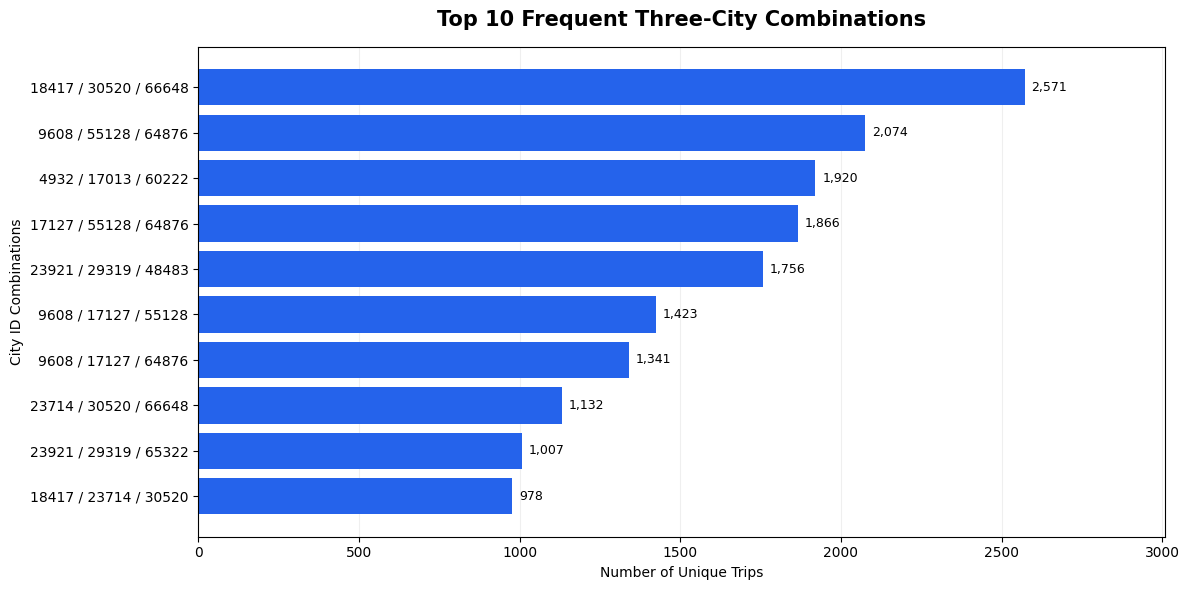

In [0]:

import matplotlib.pyplot as plt
from pyspark.sql import functions as F

# Select the ten most frequent three-city itemsets
top_triples = (
    frequent_3_df
    .orderBy(
        F.desc("trip_count"),
        F.asc("city_a"),
        F.asc("city_b"),
        F.asc("city_c")
    )
    .limit(10)
    .collect()
)

# Prepare aggregated data for plotting
labels = [
    f"{r['city_a']} / {r['city_b']} / {r['city_c']}"
    for r in top_triples
]

counts = [r["trip_count"] for r in top_triples]

# Create portfolio visualization
fig, ax = plt.subplots(figsize=(12, 6))

bars = ax.barh(
    labels[::-1],
    counts[::-1],
    color="#2563EB"
)

ax.bar_label(
    bars,
    labels=[f"{n:,}" for n in counts[::-1]],
    padding=5,
    fontsize=9
)

ax.set_title(
    "Top 10 Frequent Three-City Combinations",
    fontsize=15,
    fontweight="bold",
    pad=15
)

ax.set_xlabel("Number of Unique Trips")
ax.set_ylabel("City ID Combinations")

ax.set_xlim(0, max(counts) * 1.17)
ax.grid(axis="x", alpha=0.20)
ax.set_axisbelow(True)

plt.tight_layout()
plt.show()


### Interpretation of Frequent Three-City Combinations

The analysis generated 1,092 candidate three-city itemsets and identified 405 combinations satisfying the minimum support threshold of 0.1%.

The most frequent combination was **City 18417, City 30520, and City 66648**, observed in 2,571 unique trips (1.181% support).

The second most frequent combination (9608, 55128, 64876) appeared in 2,074 trips, while the third (4932, 17013, 60222) appeared in 1,920 trips.

These findings demonstrate recurring three-destination booking patterns that could be investigated for personalized recommendations or travel package development.

However, destination identifiers are anonymized, and further geographical validation would be necessary before applying these findings to commercial travel products.


## 11. Final Validation and Quality Assurance

This section validates the consistency of the
transaction preparation, frequent itemset mining,
and association rule calculations.

The objective is to ensure that the analytical
results are reliable and internally consistent
before publication.


In [0]:

from pyspark.sql import functions as F

# Final project audit
audit = {
    "booking_records": bookings_df.count(),
    "unique_trips": transactions_df.count(),
    "frequent_1_itemsets": frequent_1_df.count(),
    "frequent_2_itemsets": frequent_2_df.count(),
    "candidate_3_itemsets": candidate_3_df.count(),
    "frequent_3_itemsets": frequent_3_df.count(),
    "directional_rules": all_rules_df.count(),
    "qualified_rules": qualified_rules_df.count(),
    "selected_business_rules": selected_rules_df.count()
}

# Compare against previously verified results
expected = {
    "booking_records": 1166835,
    "unique_trips": 217686,
    "frequent_2_itemsets": 969,
    "candidate_3_itemsets": 1092,
    "frequent_3_itemsets": 405,
    "directional_rules": 1938,
    "qualified_rules": 1299,
    "selected_business_rules": 3
}

for metric, value in audit.items():
    print(f"{metric}: {value:,}")

for metric, expected_value in expected.items():
    assert audit[metric] == expected_value, (
        f"{metric}: expected {expected_value}, "
        f"got {audit[metric]}"
    )

# Validate trip baskets
invalid_baskets = transactions_df.filter(
    (F.col("basket_size") < 1) |
    (
        F.col("basket_size") !=
        F.size(F.array_distinct("cities"))
    )
).count()

assert invalid_baskets == 0, \
    "Invalid or duplicate-city baskets found."

assert audit["frequent_1_itemsets"] > 0
assert audit["frequent_3_itemsets"] <= audit["candidate_3_itemsets"]

print("\nFINAL AUDIT: ALL CHECKS PASSED")


booking_records: 1,166,835
unique_trips: 217,686
frequent_1_itemsets: 815
frequent_2_itemsets: 969
candidate_3_itemsets: 1,092
frequent_3_itemsets: 405
directional_rules: 1,938
qualified_rules: 1,299
selected_business_rules: 3

FINAL AUDIT: ALL CHECKS PASSED
